# Distance to a trauma center and firearm mortality

The trauma-desert argument separates two facts. How many people are shot is a question about violence. How many of those people die is also a question about minutes. A Level I or Level II trauma center is built for the second fact. Urban studies of gunshot wounds, including the Chicago trauma-desert work, find that a longer trip to a high-level center lowers survival. They do not find that the same distance produces the shooting.

This notebook maps the geographic half of that claim for every US county, then sets it beside the firearm death rate counties publish.

**Distance.** Straight-line miles from the county land centroid to the nearest open hospital that HIFLD records as an adult Level I or Level II trauma center.

**Death rate.** Firearm deaths per 100,000 people, all intents, from the County Health Rankings 2025 annual file. CHR documents that release as 2018–2022 deaths.

The rate is not case fatality. It counts suicides, homicides, unintentional shootings, and legal intervention, whether or not a trauma center could have changed the outcome. In rural counties most firearm deaths are suicides. A far county can have a high firearm death rate because of that mix, not because gunshot victims died on the way to a hospital.


## How to run

Run this notebook from the `trauma-deserts` directory, so `../data` is the repo-root data folder. The first run downloads the Census county file, the HIFLD hospital layer, and the County Health Rankings file into `../data/trauma-deserts/`. Later runs reuse those files.

```bash
cd trauma-deserts
uv venv --python 3.13 .venv
uv pip install -r requirements.txt
```

Open the notebook with that environment and run all cells. The maps are written next to the notebook.


## Setup


In [1]:
%matplotlib inline

from __future__ import annotations

import json
import re
import urllib.parse
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shapely
import statsmodels.api as sm
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from scipy.stats import pearsonr

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = False

HERE = Path.cwd()
if not (HERE / "trauma_deserts.ipynb").exists():
    raise FileNotFoundError("Run this notebook from the trauma-deserts directory.")
DATA = (HERE / "../data/trauma-deserts").resolve()
DATA.mkdir(parents=True, exist_ok=True)

USER_AGENT = "trauma-deserts-notebook/1.0 (county distance to trauma care)"
MILES_PER_METER = 1 / 1609.344
SQ_METERS_PER_SQ_MILE = 1609.344**2

# Equal-area systems in meters. National Atlas Equal Area (EPSG:2163) is fit to
# the lower 48, so Alaska and Hawaii are measured in their own systems.
REGION_CRS = {
    "conus": "EPSG:5070",
    "alaska": "EPSG:3338",
    "hawaii": (
        "+proj=aea +lat_1=8 +lat_2=18 +lat_0=13 +lon_0=-157 "
        "+x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs +type=crs"
    ),
}
STATE_FIPS = {
    "01", "02", "04", "05", "06", "08", "09", "10", "11", "12", "13", "15", "16",
    "17", "18", "19", "20", "21", "22", "23", "24", "25", "26", "27", "28", "29",
    "30", "31", "32", "33", "34", "35", "36", "37", "38", "39", "40", "41", "42",
    "44", "45", "46", "47", "48", "49", "50", "51", "53", "54", "55", "56",
}
CONUS_POSTAL = {
    "AL", "AZ", "AR", "CA", "CO", "CT", "DE", "DC", "FL", "GA", "ID", "IL", "IN",
    "IA", "KS", "KY", "LA", "ME", "MD", "MA", "MI", "MN", "MS", "MO", "MT", "NE",
    "NV", "NH", "NJ", "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
}
BIN_EDGES = [0, 5, 15, 30, np.inf]
BIN_LABELS = ["Under 5 miles", "5–15 miles", "15–30 miles", "30 miles or more"]
MISSING = "#d9d6d0"

COUNTY_URL = "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip"
CHR_URL = (
    "https://www.countyhealthrankings.org/sites/default/files/media/document/"
    "analytic_data2025_v3.csv"
)
HOSPITAL_QUERY = (
    "https://services.arcgis.com/XG15cJAlne2vxtgt/arcgis/rest/services/"
    "Hospitals_hifld/FeatureServer/0/query"
)


## Data

Three layers.

County polygons are the Census Bureau's 2023 cartographic boundaries at 1:500,000. `ALAND` is land area in square meters and becomes the density denominator. Connecticut is the nine planning regions the Census has used as county equivalents since 2022, not the eight legacy counties.

Hospitals are the HIFLD open hospitals layer (adult trauma level, status, and coordinates). The portal's own host has moved; this notebook reads the public `Hospitals_hifld` feature service that still serves that layer. The `TRAUMA` field is a free-text designation, not a clean code, so Level I and II are parsed below. Pediatric-only designations are left out. Level III and IV are left out because the claim is about high-level trauma care.

Firearm deaths are the County Health Rankings 2025 annual analytic file, measure "Firearm Fatalities," which CHR sources from NCHS mortality files. The raw value is already deaths per 100,000. Homicides in the same file are a second outcome: all methods, not firearms alone, and suppressed in many small counties.


In [2]:
def download(url: str, dest: Path) -> Path:
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    request = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
    with urllib.request.urlopen(request, timeout=180) as response:
        dest.write_bytes(response.read())
    return dest


def shift_dateline(geom):
    """Move Aleutian parts that the Census stores east of the antimeridian.

    Aleutians West is stored with some islands near longitude +180. Its unshifted
    centroid falls in central Canada. Parts with longitude above 0 are shifted
    by -360 so the borough is one shape west of mainland Alaska.
    """
    if geom is None or geom.is_empty or geom.bounds[2] <= 0:
        return geom

    def _shift(coords):
        out = np.array(coords, copy=True)
        out[..., 0] = out[..., 0] - (out[..., 0] > 0) * 360
        return out

    return shapely.transform(geom, _shift)


def adult_levels(raw) -> set[str]:
    """Adult Level I and/or II tokens in a HIFLD TRAUMA string.

    Clauses that are pediatric-only are ignored, including the misspellings in
    this file (`PEDIACTRIC`, `PEDIATIRCS`). A combined value such as
    `LEVEL I, PEDIATRIC II` counts as adult Level I. Provisional Level II counts.
    State-specific labels that never say I or II (`RTC`, `REGIONAL TRAUMA CENTER`)
    are not promoted to a level.
    """
    if not isinstance(raw, str):
        return set()
    text = raw.upper().strip()
    if text in {"", "NOT AVAILABLE", "NOT DESIGNATED", "NON-DESIGNATED", "UNCLASSIFIED"}:
        return set()
    found: set[str] = set()
    for clause in re.split(r"[,/&]|\bAND\b", text):
        clause = clause.strip()
        if not clause or ("PEDI" in clause and "ADULT" not in clause):
            continue
        normalized = re.sub(r"\b1\b", "I", clause.replace("LEVEL", " "))
        normalized = re.sub(r"\b2\b", "II", normalized)
        if re.search(r"\bII\b", normalized):
            found.add("II")
        if re.search(r"\bI\b", normalized):
            found.add("I")
    return found


def highest_adult_level(raw) -> str | None:
    levels = adult_levels(raw)
    if "I" in levels:
        return "I"
    if "II" in levels:
        return "II"
    return None


PARSER_CASES = {
    "1": "I",
    "3": None,
    "I": "I",
    "I , II PEDIATIRCS": "I",
    "I , II PEDIATRICS": "I",
    "I PEDIATRIC": None,
    "I, I PEDIATRIC": "I",
    "I, II PEDIATRIC": "I",
    "I,PEDIATRIC I": "I",
    "II": "II",
    "II PEDIATRIC": None,
    "II, II PEDIATRIC": "II",
    "III": None,
    "IV": None,
    "LEVEL 1": "I",
    "LEVEL I": "I",
    "LEVEL I ADULT & PEDIATRIC": "I",
    "LEVEL I PEDIATRIC": None,
    "LEVEL I, I PEDIATRIC": "I",
    "LEVEL I, PEDIACTRIC II": "I",
    "LEVEL I, PEDIATRIC": "I",
    "LEVEL I, PEDIATRIC I": "I",
    "LEVEL I, PEDIATRIC II": "I",
    "LEVEL I, PEDIATRICS I": "I",
    "LEVEL II": "II",
    "LEVEL II / PEDIATRIC": "II",
    "LEVEL II PEDIATRIC": None,
    "LEVEL II, PEDIACTRICS II": "II",
    "LEVEL II, PEDIATRIC II": "II",
    "LEVEL II, PEDIATRICS III": "II",
    "LEVEL III": None,
    "LEVEL III/PEDIATIC": None,
    "LEVEL IV": None,
    "LEVEL V": None,
    "PEDIATRIC LEVEL I": None,
    "PEDIATRIC LEVEL II": None,
    "PROVISIONAL LEVEL II": "II",
    "PROVISIONAL LEVEL III": None,
    "REGIONAL TRAUMA CENTER": None,
    "NOT AVAILABLE": None,
    "RTC": None,
    "RTH": None,
    "TRAUMA SYSTEM HOSPITAL": None,
}
for raw, expected in PARSER_CASES.items():
    got = highest_adult_level(raw)
    if got != expected:
        raise AssertionError(f"{raw!r}: expected {expected!r}, got {got!r}")


In [3]:
county_zip = download(COUNTY_URL, DATA / "cb_2023_us_county_500k.zip")
counties = gpd.read_file(county_zip)
counties = counties[counties["STATEFP"].isin(STATE_FIPS)].copy()
counties["geometry"] = counties.geometry.apply(shift_dateline)
counties["region"] = np.where(
    counties["STATEFP"].eq("02"),
    "alaska",
    np.where(counties["STATEFP"].eq("15"), "hawaii", "conus"),
)
print(f"Counties: {len(counties):,}  (conus {(counties.region == 'conus').sum():,}, alaska {(counties.region == 'alaska').sum():,}, hawaii {(counties.region == 'hawaii').sum():,})")


Counties: 3,144  (conus 3,109, alaska 30, hawaii 5)


In [4]:
def load_hospitals(cache: Path) -> gpd.GeoDataFrame:
    if cache.exists() and cache.stat().st_size > 0:
        hospitals = gpd.read_file(cache)
        hospitals.columns = [c.lower() for c in hospitals.columns]
        return hospitals

    frames = []
    offset = 0
    page_size = 2000
    while True:
        query = urllib.parse.urlencode(
            {
                "where": "STATUS='OPEN'",
                "outFields": "ID,NAME,CITY,STATE,TRAUMA,LATITUDE,LONGITUDE,STATUS",
                "returnGeometry": "true",
                "outSR": "4326",
                "f": "geojson",
                "resultOffset": str(offset),
                "resultRecordCount": str(page_size),
            }
        )
        request = urllib.request.Request(
            f"{HOSPITAL_QUERY}?{query}", headers={"User-Agent": USER_AGENT}
        )
        with urllib.request.urlopen(request, timeout=180) as response:
            payload = json.loads(response.read().decode("utf-8"))
        if "error" in payload:
            raise RuntimeError(payload["error"])
        frame = gpd.GeoDataFrame.from_features(payload.get("features", []), crs="EPSG:4326")
        if frame.empty:
            break
        frames.append(frame)
        if len(frame) < page_size:
            break
        offset += page_size

    hospitals = pd.concat(frames, ignore_index=True)
    hospitals = gpd.GeoDataFrame(hospitals, geometry="geometry", crs="EPSG:4326")
    hospitals.columns = [c.lower() for c in hospitals.columns]
    hospitals.to_file(cache, driver="GeoJSON")
    return hospitals


hospitals = load_hospitals(DATA / "hifld_hospitals_open.geojson")
print(f"Open hospitals: {len(hospitals):,}")
print(hospitals["trauma"].value_counts(dropna=False).head(12))


Open hospitals: 7,216
trauma
NOT AVAILABLE    5253
LEVEL IV          614
LEVEL III         242
LEVEL II          200
IV                179
III               160
LEVEL I           123
II                108
I                  77
TRH                57
CTH                24
LEVEL V            17
Name: count, dtype: int64


In [5]:
chr_path = download(CHR_URL, DATA / "analytic_data2025_v3.csv")
chr_raw = pd.read_csv(
    chr_path,
    dtype={"5-digit FIPS Code": str, "State FIPS Code": str, "County FIPS Code": str},
    low_memory=False,
)
# The file's second row repeats the column names as machine codes.
chr_raw = chr_raw[chr_raw["5-digit FIPS Code"].str.fullmatch(r"\d{5}", na=False)]
chr_raw = chr_raw[chr_raw["County FIPS Code"] != "000"]
deaths = chr_raw.rename(
    columns={
        "5-digit FIPS Code": "fips",
        "State Abbreviation": "state_postal",
        "Name": "chr_name",
        "Firearm Fatalities raw value": "firearm_rate",
        "Firearm Fatalities numerator": "firearm_deaths",
        "Firearm Fatalities denominator": "firearm_person_years",
        "Homicides raw value": "homicide_rate",
        "Population raw value": "population",
        "% Non-Hispanic Black raw value": "pct_black",
        "% Hispanic raw value": "pct_hispanic",
        "% Non-Hispanic White raw value": "pct_white",
        "% American Indian or Alaska Native raw value": "pct_aian",
        "% Asian raw value": "pct_asian",
        "% Rural raw value": "pct_rural",
        "Firearm Fatalities (Black)": "firearm_black",
        "Firearm Fatalities (White)": "firearm_white",
        "Firearm Fatalities (Hispanic)": "firearm_hispanic",
        "Firearm Fatalities (AIAN)": "firearm_aian",
        "Firearm Fatalities (Asian)": "firearm_asian",
    }
)[
    [
        "fips",
        "state_postal",
        "chr_name",
        "firearm_rate",
        "firearm_deaths",
        "firearm_person_years",
        "homicide_rate",
        "population",
        "pct_black",
        "pct_hispanic",
        "pct_white",
        "pct_aian",
        "pct_asian",
        "pct_rural",
        "firearm_black",
        "firearm_white",
        "firearm_hispanic",
        "firearm_aian",
        "firearm_asian",
    ]
].copy()
for col in [
    "firearm_rate",
    "firearm_deaths",
    "firearm_person_years",
    "homicide_rate",
    "population",
    "pct_black",
    "pct_hispanic",
    "pct_white",
    "pct_aian",
    "pct_asian",
    "pct_rural",
    "firearm_black",
    "firearm_white",
    "firearm_hispanic",
    "firearm_aian",
    "firearm_asian",
]:
    deaths[col] = pd.to_numeric(deaths[col], errors="coerce")
for col in ["pct_black", "pct_hispanic", "pct_white", "pct_aian", "pct_asian", "pct_rural"]:
    deaths[col] = deaths[col] * 100

counties = counties.merge(deaths, left_on="GEOID", right_on="fips", how="left", validate="1:1")
missing_join = int(counties["fips"].isna().sum())
if missing_join:
    raise AssertionError(f"{missing_join} counties did not match a CHR row")
print(f"Joined rows: {len(counties):,}")
print(
    "Published firearm rate: "
    f"{counties['firearm_rate'].notna().sum():,}    "
    "published homicide rate: "
    f"{counties['homicide_rate'].notna().sum():,}"
)


Joined rows: 3,144
Published firearm rate: 2,306    published homicide rate: 1,425


## Which hospitals count

HIFLD stores trauma level as text entered from state lists. The parser above was checked against every phrasing in the copy of the file this notebook was written against. Strings that still do not resolve are printed, so a later extract cannot silently drop a new code.

A center counts if it is open and the text names an adult Level I or Level II. Pediatric-only centers stay in the hospital file and out of the distance calculation. The file does not say whether a military or specialty hospital accepts civilian trauma.


In [6]:
hospitals["adult_level"] = hospitals["trauma"].map(highest_adult_level)
known = set(PARSER_CASES)
observed = {str(v).strip() for v in hospitals["trauma"].dropna().unique()}
unknown = sorted(observed - known)
if unknown:
    print("Trauma strings outside the tested vocabulary (still parsed by the same rules):")
    for value in unknown:
        print(" ", repr(value), "->", highest_adult_level(value))

centers = hospitals[hospitals["adult_level"].notna()].copy()
centers["state"] = centers["state"].astype("string").str.strip().str.upper()
aleutian = centers["state"].eq("AK") & centers.geometry.x.gt(0)
if aleutian.any():
    centers.loc[aleutian, "geometry"] = centers.loc[aleutian].geometry.apply(shift_dateline)
centers["region"] = np.select(
    [centers["state"].eq("AK"), centers["state"].eq("HI"), centers["state"].isin(CONUS_POSTAL)],
    ["alaska", "hawaii", "conus"],
    default=None,
)
centers = centers[centers["region"].notna() & centers.geometry.notna() & ~centers.geometry.is_empty].copy()

level_counts = centers.groupby(["region", "adult_level"]).size().unstack(fill_value=0)
print(f"Adult Level I/II centers used: {len(centers):,}")
display(level_counts)
if not (150 <= len(centers) <= 900):
    raise AssertionError(f"Unexpected center count: {len(centers)}")
for region in ("conus", "alaska", "hawaii"):
    n_region = int((centers["region"] == region).sum())
    if n_region < 1:
        raise AssertionError(f"No Level I/II center in {region}")


Trauma strings outside the tested vocabulary (still parsed by the same rules):
  'AREA' -> None
  'ATH' -> None
  'CTH' -> None
  'LEVEL III PEDIATRIC' -> None
  'LEVEL III TRAUMA' -> None
  'LEVEL III/PEDIATRIC' -> None
  'NON-DESIGNATED' -> None
  'NOT DESIGNATED' -> None
  'PARC' -> None
  'PEDIATRIC' -> None
  'PEDIATRIC 1' -> None
  'PEDIATRIC I' -> None
  'PEDIATRICS I' -> None
  'RPTC' -> None
  'TRF' -> None
  'TRH' -> None
  'UNCLASSIFIED' -> None
Adult Level I/II centers used: 564


adult_level,I,II
region,,
alaska,0,3
conus,239,321
hawaii,1,0


## Distance

Each county is measured in a regional system with units of meters: CONUS Albers (EPSG:5070), Alaska Albers (EPSG:3338), and a Hawaii Albers centered on 157°W. A lower-48 county can match a center in another lower-48 state. Alaska is matched only to Alaska centers, and Hawaii only to Hawaii centers.

The point used for the county is the centroid of the land polygon in that projected system. In a large county that point can sit far from the town where people live. The distance is straight-line miles, not an ambulance drive.


In [7]:
def nearest_center(counties_region: gpd.GeoDataFrame, centers_region: gpd.GeoDataFrame, crs: str) -> pd.DataFrame:
    counties_m = counties_region.to_crs(crs)
    centers_m = centers_region.to_crs(crs)
    centroids = counties_m.geometry.centroid
    tree = cKDTree(np.column_stack([centers_m.geometry.x, centers_m.geometry.y]))
    distances_m, indices = tree.query(np.column_stack([centroids.x, centroids.y]), k=1)
    nearest = centers_region.iloc[indices]
    return pd.DataFrame(
        {
            "GEOID": counties_region["GEOID"].to_numpy(),
            "distance_miles": distances_m * MILES_PER_METER,
            "nearest_center": nearest["name"].to_numpy(),
            "nearest_level": nearest["adult_level"].to_numpy(),
        }
    )


pieces = [
    nearest_center(counties[counties["region"] == region], centers[centers["region"] == region], crs)
    for region, crs in REGION_CRS.items()
]
nearest = pd.concat(pieces, ignore_index=True)
counties = counties.drop(columns=[c for c in ("distance_miles", "nearest_center", "nearest_level") if c in counties.columns])
counties = counties.merge(nearest, on="GEOID", how="left", validate="1:1")

if not np.isfinite(counties["distance_miles"]).all() or (counties["distance_miles"] < 0).any():
    raise AssertionError("Distance calculation produced missing or negative miles")
median_miles = float(counties["distance_miles"].median())
if not 5 <= median_miles <= 80:
    raise AssertionError(f"Median distance {median_miles:.1f} miles is outside the expected range")

counties["distance_bin"] = pd.cut(
    counties["distance_miles"],
    bins=BIN_EDGES,
    labels=BIN_LABELS,
    right=False,
    include_lowest=True,
)
counties["land_sq_miles"] = counties["ALAND"] / SQ_METERS_PER_SQ_MILE
counties["density"] = counties["population"] / counties["land_sq_miles"]
counties["log_density"] = np.log10(counties["density"].where(counties["density"] > 0))

print(counties["distance_miles"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))
print()
print("Nearest counties")
display(
    counties.nsmallest(5, "distance_miles")[
        ["NAMELSAD", "STATE_NAME", "distance_miles", "nearest_center", "nearest_level", "firearm_rate"]
    ]
)
print("Farthest counties")
display(
    counties.nlargest(5, "distance_miles")[
        ["NAMELSAD", "STATE_NAME", "distance_miles", "nearest_center", "nearest_level", "firearm_rate"]
    ]
)


count   3,144.00
mean       58.90
std        62.90
min         0.10
5%          6.10
25%        25.80
50%        43.00
75%        71.10
95%       162.20
max     1,000.90
Name: distance_miles, dtype: float64

Nearest counties


,NAMELSAD,STATE_NAME,distance_miles,nearest_center,nearest_level,firearm_rate
1650,Genesee County,Michigan,0.10,HURLEY MEDICAL CENTER,I,21.20
1171,Suffolk County,Massachusetts,0.13,BOSTON MEDICAL CENTER - MENINO CAMPUS,I,5.82
722,Queens County,New York,0.29,JAMAICA HOSPITAL MEDICAL CENTER,I,2.54
1307,Gwinnett County,Georgia,0.37,GWINNETT HOSPITAL SYSTEM,II,12.11
453,St. Louis County,Missouri,0.38,MERCY HOSPITAL ST. LOUIS,I,24.17


Farthest counties


,NAMELSAD,STATE_NAME,distance_miles,nearest_center,nearest_level,firearm_rate
1414,Aleutians West Census Area,Alaska,"1,000.91",CENTRAL PENINSULA GENERAL HOSPITAL,II,NaN
305,Ketchikan Gateway Borough,Alaska,782.63,ALASKA NATIVE MEDICAL CENTER - ANMC,II,NaN
2991,Wrangell City and Borough,Alaska,717.64,ALASKA NATIVE MEDICAL CENTER - ANMC,II,NaN
1413,Prince of Wales-Hyder Census Area,Alaska,709.90,ALASKA NATIVE MEDICAL CENTER - ANMC,II,NaN
1008,Petersburg Borough,Alaska,658.52,ALASKA NATIVE MEDICAL CENTER - ANMC,II,NaN


## Association

The regression is ordinary least squares of the published firearm rate on straight-line distance and log10 population density. Standard errors are HC1. Each county is one observation in that fit, which gives a county of a thousand people the same vote as Los Angeles. A second fit weights by population. A third drops the farthest 1% of counties, because the Aleutians and a handful of other boroughs sit hundreds of miles out and can lever a line.

Density is in the model because rural counties are both farther from trauma centers and different in the mix of firearm deaths. The distance coefficient is the association that remains after that control. It is not an effect of moving a trauma center.

Homicide rates from the same file are fit the same way. That outcome is closer to interpersonal violence than the all-intent firearm rate, and it is still not the share of shooting victims who die. CHR suppresses it in most small counties.


In [8]:
def fit_frame(frame: pd.DataFrame, outcome: str) -> pd.DataFrame:
    columns = [outcome, "distance_miles", "log_density", "population"]
    out = frame.dropna(subset=columns).copy()
    return out[out["population"] > 0]


def distance_row(label: str, model, n: int) -> dict:
    coef = float(model.params["distance_miles"]) * 10
    low, high = model.conf_int().loc["distance_miles"].tolist()
    return {
        "model": label,
        "per 10 miles": coef,
        "CI low": low * 10,
        "CI high": high * 10,
        "p": float(model.pvalues["distance_miles"]),
        "R²": float(model.rsquared),
        "n": n,
    }


def fit_ols(frame: pd.DataFrame, outcome: str, weights=None):
    y = frame[outcome]
    x = sm.add_constant(frame[["distance_miles", "log_density"]])
    if weights is None:
        return sm.OLS(y, x).fit(cov_type="HC1")
    return sm.WLS(y, x, weights=weights).fit(cov_type="HC1")


firearm = fit_frame(counties, "firearm_rate")
homicide = fit_frame(counties, "homicide_rate")
cap = float(firearm["distance_miles"].quantile(0.99))
firearm_core = firearm[firearm["distance_miles"] <= cap]

ols = fit_ols(firearm, "firearm_rate")
wls = fit_ols(firearm, "firearm_rate", weights=firearm["population"])
ols_core = fit_ols(firearm_core, "firearm_rate")
ols_homicide = fit_ols(homicide, "homicide_rate")
unadjusted = sm.OLS(
    firearm["firearm_rate"], sm.add_constant(firearm["distance_miles"])
).fit(cov_type="HC1")

raw_r, raw_p = pearsonr(firearm["distance_miles"], firearm["firearm_rate"])
density_r, _ = pearsonr(firearm["distance_miles"], firearm["log_density"])

model_table = pd.DataFrame(
    [
        distance_row("Firearm rate, distance only", unadjusted, len(firearm)),
        distance_row("Firearm rate, density held fixed", ols, len(firearm)),
        distance_row("Firearm rate, density held fixed, weighted by population", wls, len(firearm)),
        distance_row(
            f"Firearm rate, density held fixed, distance at or below {cap:.0f} miles",
            ols_core,
            len(firearm_core),
        ),
        distance_row("Homicide rate, density held fixed", ols_homicide, len(homicide)),
    ]
)
def signed(value: float) -> str:
    return f"{value:+.2f}" if abs(value) >= 0.05 else f"{value:+.3f}"


pretty = model_table.copy()
for column in ("per 10 miles", "CI low", "CI high"):
    pretty[column] = model_table[column].map(signed)
pretty["p"] = model_table["p"].map(lambda value: "<0.001" if value < 0.001 else f"{value:.3f}")
pretty["R²"] = model_table["R²"].map(lambda value: f"{value:.2f}")
pretty["n"] = model_table["n"].map(lambda value: f"{int(value):,}")
display(pretty)

print(
    f"Unweighted correlation of distance and the firearm rate: r = {raw_r:.2f} ({raw_p:.3g}). "
    f"Correlation of distance and log density: r = {density_r:.2f}."
)
print(
    "Log-density coefficient in the main firearm model: "
    f"{ols.params['log_density']:+.2f} deaths per 100,000 per tenfold increase in density "
    f"(HC1 p = {ols.pvalues['log_density']:.3g})."
)


def weighted_mean(frame: pd.DataFrame, value: str) -> float:
    usable = frame.dropna(subset=[value, "population"])
    usable = usable[usable["population"] > 0]
    if usable.empty or usable["population"].sum() == 0:
        return np.nan
    return float(np.average(usable[value], weights=usable["population"]))


rows = []
for label in BIN_LABELS:
    part = counties[counties["distance_bin"] == label]
    published = part[part["firearm_rate"].notna()]
    rows.append(
        {
            "distance": label,
            "counties": len(part),
            "population": part["population"].sum(min_count=1),
            "share with a firearm rate": part["firearm_rate"].notna().mean(),
            "median firearm rate": published["firearm_rate"].median(),
            "population-weighted firearm rate": weighted_mean(part, "firearm_rate"),
            "share with a homicide rate": part["homicide_rate"].notna().mean(),
            "population-weighted homicide rate": weighted_mean(part, "homicide_rate"),
        }
    )
bin_table = pd.DataFrame(rows)
display(bin_table)


def p_text(p: float) -> str:
    if p < 0.001:
        return "p < 0.001"
    return f"p = {p:.3f}"


def interval_clause(low: float, high: float) -> str:
    if low > 0:
        return "above zero"
    if high < 0:
        return "below zero"
    return "including zero"


near = bin_table.loc[bin_table["distance"] == BIN_LABELS[0]].iloc[0]
far = bin_table.loc[bin_table["distance"] == BIN_LABELS[-1]].iloc[0]
main = model_table.loc[model_table["model"] == "Firearm rate, density held fixed"].iloc[0]
weighted = model_table.loc[
    model_table["model"] == "Firearm rate, density held fixed, weighted by population"
].iloc[0]
hom_row = model_table.loc[model_table["model"] == "Homicide rate, density held fixed"].iloc[0]

findings = (
    f"Among {len(firearm):,} counties with a published firearm rate, people in counties under 5 miles "
    f"from a Level I or II center have a population-weighted rate of {near['population-weighted firearm rate']:.1f} "
    f"firearm deaths per 100,000. People in counties 30 miles or more away have a rate of "
    f"{far['population-weighted firearm rate']:.1f}. Those far counties are also the ones where CHR most often "
    f"has no rate to publish ({far['share with a firearm rate']:.0%} published, against "
    f"{near['share with a firearm rate']:.0%} of the near counties). "
    f"Holding log population density fixed, the unweighted county fit gives {signed(main['per 10 miles'])} deaths "
    f"per 100,000 for each additional 10 miles (95% CI {signed(main['CI low'])} to {signed(main['CI high'])}, "
    f"{p_text(main['p'])}, interval {interval_clause(main['CI low'], main['CI high'])}). "
    f"The same model weighted by population gives {signed(weighted['per 10 miles'])} "
    f"(95% CI {signed(weighted['CI low'])} to {signed(weighted['CI high'])}, {p_text(weighted['p'])}). "
    f"The two predictors together have R² = {main['R²']:.2f}. "
    f"For homicide, the density-controlled distance slope is {signed(hom_row['per 10 miles'])} per 10 miles "
    f"(95% CI {signed(hom_row['CI low'])} to {signed(hom_row['CI high'])}, {p_text(hom_row['p'])}, "
    f"n = {int(hom_row['n']):,})."
)
print(findings)
counties.to_csv(DATA / "county_distance.csv", index=False)


,model,per 10 miles,CI low,CI high,p,R²,n
0,"Firearm rate, distance only",+0.53,+0.42,+0.64,<0.001,0.09,"2,306"
1,"Firearm rate, density held fixed",+0.10,+0.002,+0.20,0.046,0.21,"2,306"
2,"Firearm rate, density held fixed, weighted by ...",-0.06,-0.19,+0.06,0.321,0.09,"2,306"
3,"Firearm rate, density held fixed, distance at ...",+0.09,-0.013,+0.20,0.085,0.18,"2,282"
4,"Homicide rate, density held fixed",-0.012,-0.10,+0.08,0.789,0.06,"1,425"


Unweighted correlation of distance and the firearm rate: r = 0.31 (4.5e-51). Correlation of distance and log density: r = -0.60.
Log-density coefficient in the main firearm model: -5.34 deaths per 100,000 per tenfold increase in density (HC1 p = 9.64e-45).


,distance,counties,population,share with a firearm rate,median firearm rate,population-weighted firearm rate,share with a homicide rate,population-weighted homicide rate
0,Under 5 miles,133,"77,809,114.00",0.98,13.52,14.03,0.96,9.25
1,5–15 miles,227,"104,707,369.00",0.96,12.40,11.96,0.84,6.59
2,15–30 miles,627,"75,520,463.00",0.89,14.39,12.20,0.59,4.64
3,30 miles or more,2157,"76,877,949.00",0.65,18.27,16.28,0.34,6.83


Among 2,306 counties with a published firearm rate, people in counties under 5 miles from a Level I or II center have a population-weighted rate of 14.0 firearm deaths per 100,000. People in counties 30 miles or more away have a rate of 16.3. Those far counties are also the ones where CHR most often has no rate to publish (65% published, against 98% of the near counties). Holding log population density fixed, the unweighted county fit gives +0.10 deaths per 100,000 for each additional 10 miles (95% CI +0.002 to +0.20, p = 0.046, interval above zero). The same model weighted by population gives -0.06 (95% CI -0.19 to +0.06, p = 0.321). The two predictors together have R² = 0.21. For homicide, the density-controlled distance slope is -0.012 per 10 miles (95% CI -0.10 to +0.08, p = 0.789, n = 1,425).


## Maps

Both figures use one county map. Alaska and Hawaii are insets. Honolulu's display is clipped to the main islands so the Northwestern Hawaiian Islands do not shrink Oahu; the distance for Honolulu was computed from the full county.

Gray counties have no published firearm rate.


In [ ]:
def draw_region(ax, part: gpd.GeoDataFrame, crs: str, colors: list):
    projected = part.to_crs(crs)
    projected.plot(ax=ax, color=colors, linewidth=0.12, edgecolor="white")
    projected.dissolve(by="STATEFP").boundary.plot(ax=ax, color="#2a2a2a", linewidth=0.35)
    minx, miny, maxx, maxy = projected.total_bounds
    pad_x = (maxx - minx) * 0.04
    pad_y = (maxy - miny) * 0.04
    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def hawaii_main_islands(part: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    window = shapely.box(-161.5, 18.85, -154.7, 22.35)
    clipped = part.clip(window)
    return clipped[~clipped.geometry.is_empty].copy()


def draw_country(fig, box, gdf):
    """Draw the lower 48 with Alaska and Hawaii insets. Counties carry a _color column."""
    left, bottom, width, height = box
    ax = fig.add_axes([left, bottom + height * 0.22, width * 0.86, height * 0.76])
    ak = fig.add_axes([left + width * 0.02, bottom, width * 0.30, height * 0.20])
    hi = fig.add_axes([left + width * 0.36, bottom + height * 0.015, width * 0.24, height * 0.17])
    pieces = {
        "conus": (ax, gdf[gdf["region"] == "conus"]),
        "alaska": (ak, gdf[gdf["region"] == "alaska"]),
        "hawaii": (hi, hawaii_main_islands(gdf[gdf["region"] == "hawaii"])),
    }
    for region, (axis, part) in pieces.items():
        draw_region(axis, part, REGION_CRS[region], part["_color"].tolist())
    for axis, label in ((ak, "Alaska"), (hi, "Hawaii")):
        axis.set_title(label, loc="left", fontsize=8, color="#333333", pad=1)
        for spine in axis.spines.values():
            spine.set_visible(True)
            spine.set_color("#d0d0d0")
            spine.set_linewidth(0.6)
    return ax


## Firearm mortality and distance, by rank

Counties with a published firearm rate are split into thirds on distance and thirds on the death rate. A county on the diagonal is in step: a low death rate with a nearby center, a middle rate with a middle distance, or a high rate with a long distance. A county off the diagonal has more Level I or II access than counties with a similar death rate, or less.

The lower maps are population composition. County Health Rankings publishes a race-specific firearm rate for only a minority of counties, so those rates cannot fill a national map. Hispanic origin overlaps the race categories, so the shares are not slices of one total.


,death rank,distance rank,counties,people,Black,Hispanic,White,AIAN
0,lower,near,397,"149,326,956.00",10.19,21.95,54.86,0.96
1,lower,middle,231,"19,964,870.00",5.10,17.95,70.67,1.07
2,lower,far,141,"12,651,670.00",4.12,34.83,53.42,1.63
3,middle,near,233,"66,181,152.00",15.07,21.57,55.80,1.07
4,middle,middle,284,"17,328,604.00",9.86,13.04,72.31,1.59
5,middle,far,251,"11,191,865.00",6.07,13.12,74.93,2.66
6,higher,near,139,"30,914,864.00",30.51,10.87,51.98,1.05
7,higher,middle,253,"8,581,772.00",19.59,8.87,66.47,2.24
8,higher,far,377,"12,318,838.00",14.37,13.48,63.70,5.54


,class,counties,people,Black,Hispanic,White,AIAN,Asian
0,in step,1058,"178,974,398.00",10.45,20.51,57.16,1.34,8.72
1,more centers than the death rate,625,"105,677,788.00",19.95,17.41,55.55,1.16,4.07
2,fewer centers than the death rate,623,"43,808,405.00",5.06,21.59,66.77,1.64,3.24


With composition held fixed, each county equal: +0.47 deaths per 100,000 per 10 miles (95% CI +0.36 to +0.57, p < 0.001). Non-Hispanic Black: +2.62 per 10 percentage points (95% CI +2.34 to +2.89, p < 0.001). Hispanic: -0.28 per 10 percentage points (95% CI -0.52 to -0.04, p = 0.024). American Indian or Alaska Native: +1.64 per 10 percentage points (95% CI +1.05 to +2.22, p < 0.001). Asian: -6.55 per 10 percentage points (95% CI -7.72 to -5.38, p < 0.001).
The same model weighted by population: +0.36 deaths per 100,000 per 10 miles (95% CI +0.25 to +0.47, p < 0.001). Non-Hispanic Black: +2.98 per 10 percentage points (95% CI +2.42 to +3.55, p < 0.001). Hispanic: -0.38 per 10 percentage points (95% CI -0.65 to -0.10, p = 0.008). American Indian or Alaska Native: +3.21 per 10 percentage points (95% CI +2.07 to +4.34, p < 0.001). Asian: -3.54 per 10 percentage points (95% CI -4.46 to -2.61, p < 0.001).
With composition and log density held fixed, each county equal: +0.13 deaths per 100,00

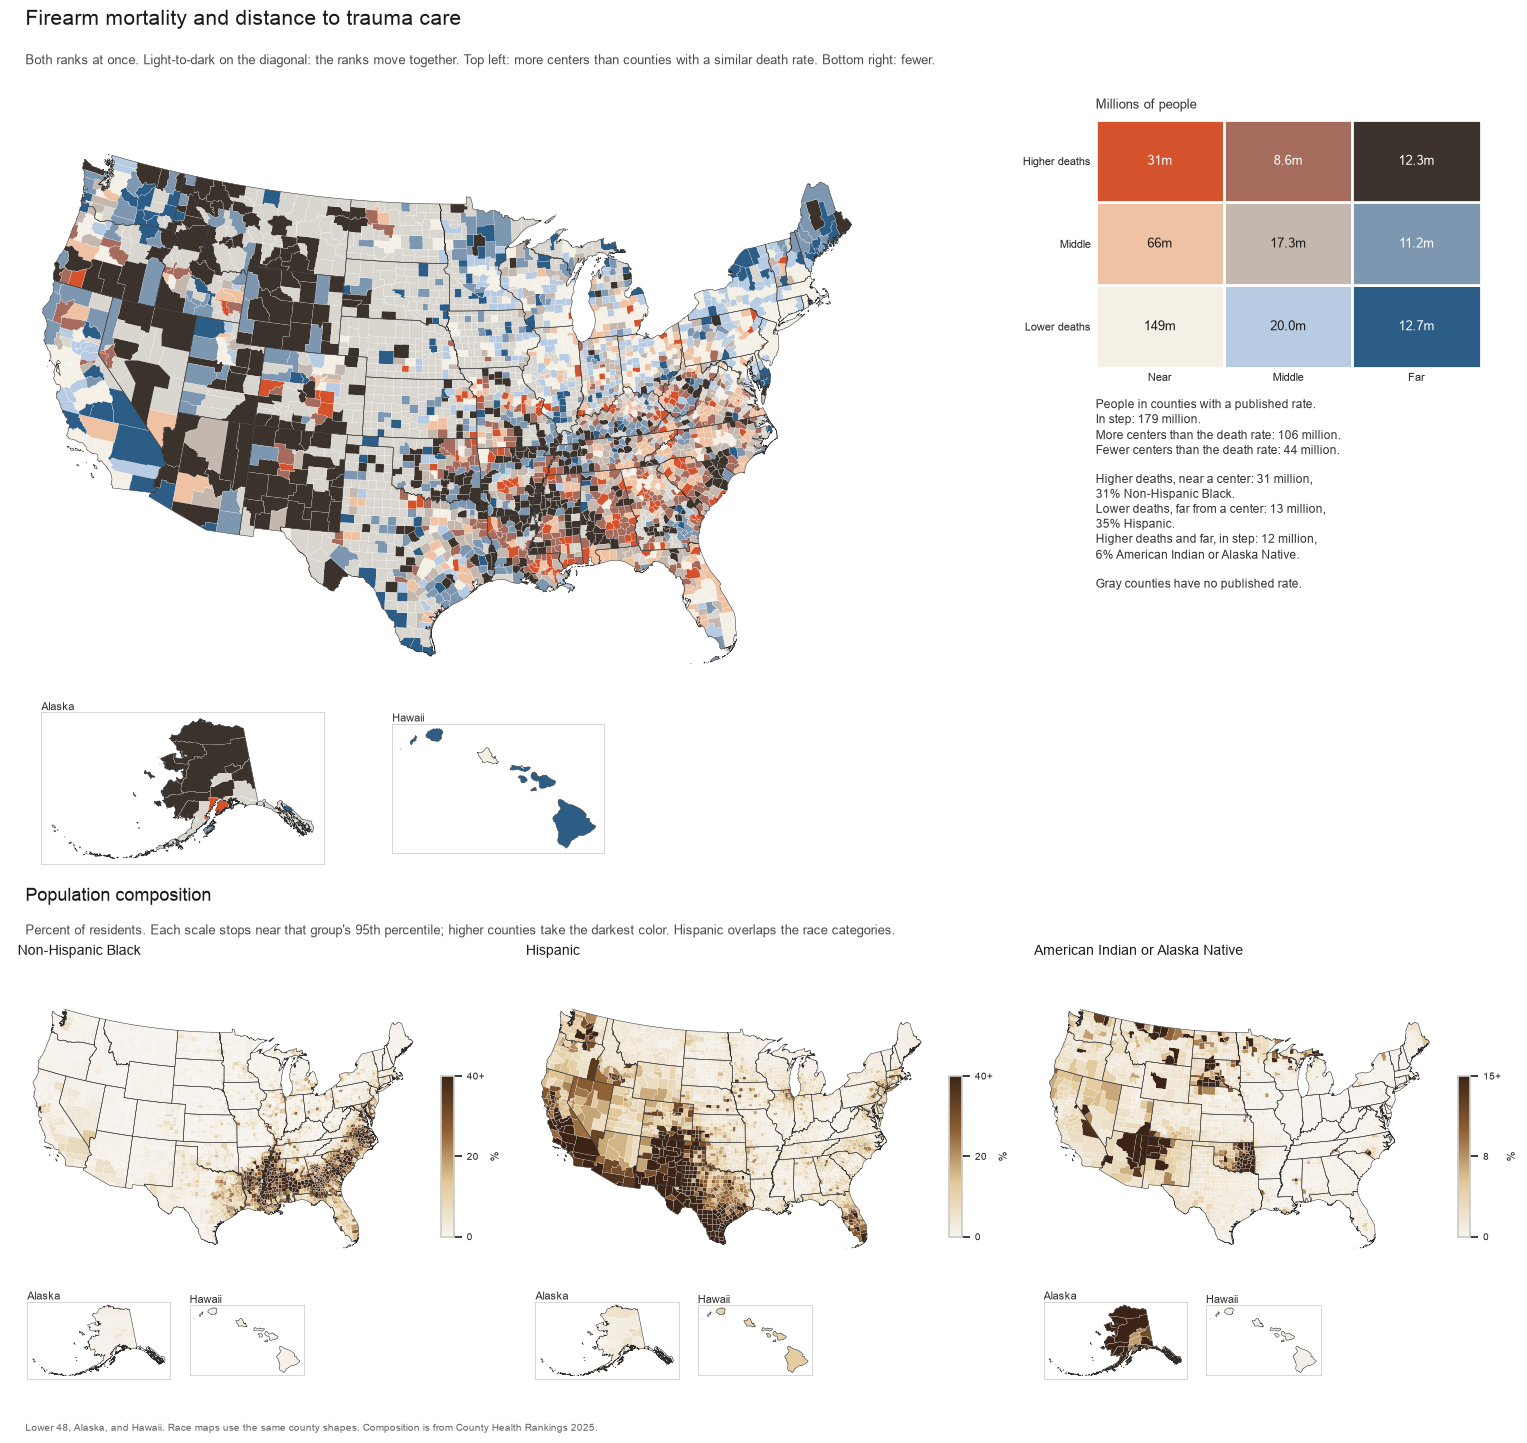

In [10]:
BIVARIATE = {
    ("lower", "near"): "#f4f0e6",
    ("lower", "middle"): "#b7cbe2",
    ("lower", "far"): "#2c5d86",
    ("middle", "near"): "#f0c2a4",
    ("middle", "middle"): "#c4b7ad",
    ("middle", "far"): "#7e97b0",
    ("higher", "near"): "#d4532c",
    ("higher", "middle"): "#a56b5c",
    ("higher", "far"): "#3c322c",
}
RANK_DISTANCE = {"near": 0, "middle": 1, "far": 2}
RANK_DEATH = {"lower": 0, "middle": 1, "higher": 2}
RACE_CMAP = LinearSegmentedColormap.from_list(
    "share", ["#f7f4ef", "#e2c99a", "#8d5e32", "#3b2416"]
)


def weighted_share(frame: pd.DataFrame, column: str) -> float:
    usable = frame.dropna(subset=[column, "population"])
    usable = usable[usable["population"] > 0]
    if usable.empty:
        return float("nan")
    return float(np.average(usable[column], weights=usable["population"]))


def millions(people: float) -> str:
    value = people / 1e6
    if value >= 20:
        return f"{value:.0f}m"
    return f"{value:.1f}m"


def ink(hex_color: str) -> str:
    channel = [int(hex_color[i : i + 2], 16) for i in (1, 3, 5)]
    luminance = 0.299 * channel[0] + 0.587 * channel[1] + 0.114 * channel[2]
    return "#ffffff" if luminance < 150 else "#1a1a1a"


published = counties.dropna(subset=["firearm_rate", "distance_miles", "population"]).copy()
published = published[published["population"] > 0]
published["distance_rank"] = pd.qcut(
    published["distance_miles"], 3, labels=["near", "middle", "far"]
)
published["death_rank"] = pd.qcut(
    published["firearm_rate"], 3, labels=["lower", "middle", "higher"]
)
published["rank_gap"] = (
    published["death_rank"].astype(str).map(RANK_DEATH)
    - published["distance_rank"].astype(str).map(RANK_DISTANCE)
)
published["skew"] = np.where(
    published["rank_gap"].gt(0),
    "more centers than the death rate",
    np.where(published["rank_gap"].lt(0), "fewer centers than the death rate", "in step"),
)

cell_rows = []
for death_rank in ["lower", "middle", "higher"]:
    for distance_rank in ["near", "middle", "far"]:
        part = published[
            (published["death_rank"] == death_rank) & (published["distance_rank"] == distance_rank)
        ]
        cell_rows.append(
            {
                "death rank": death_rank,
                "distance rank": distance_rank,
                "counties": len(part),
                "people": part["population"].sum(),
                "Black": weighted_share(part, "pct_black"),
                "Hispanic": weighted_share(part, "pct_hispanic"),
                "White": weighted_share(part, "pct_white"),
                "AIAN": weighted_share(part, "pct_aian"),
            }
        )
cell_table = pd.DataFrame(cell_rows)
display(cell_table)

skew_rows = []
for label in ["in step", "more centers than the death rate", "fewer centers than the death rate"]:
    part = published[published["skew"] == label]
    skew_rows.append(
        {
            "class": label,
            "counties": len(part),
            "people": part["population"].sum(),
            "Black": weighted_share(part, "pct_black"),
            "Hispanic": weighted_share(part, "pct_hispanic"),
            "White": weighted_share(part, "pct_white"),
            "AIAN": weighted_share(part, "pct_aian"),
            "Asian": weighted_share(part, "pct_asian"),
        }
    )
skew_table = pd.DataFrame(skew_rows)
display(skew_table)

race_x = sm.add_constant(
    published[["distance_miles", "pct_black", "pct_hispanic", "pct_aian", "pct_asian"]]
)
race_model = sm.OLS(published["firearm_rate"], race_x).fit(cov_type="HC1")
race_weighted = sm.WLS(
    published["firearm_rate"], race_x, weights=published["population"]
).fit(cov_type="HC1")


def race_line(model, label: str) -> str:
    distance = float(model.params["distance_miles"]) * 10
    low, high = (model.conf_int().loc["distance_miles"] * 10).tolist()
    pieces = [
        f"{label}: {distance:+.2f} deaths per 100,000 per 10 miles "
        f"(95% CI {low:+.2f} to {high:+.2f}, {p_text(float(model.pvalues['distance_miles']))})."
    ]
    for name, column in [
        ("Non-Hispanic Black", "pct_black"),
        ("Hispanic", "pct_hispanic"),
        ("American Indian or Alaska Native", "pct_aian"),
        ("Asian", "pct_asian"),
    ]:
        coef = float(model.params[column]) * 10
        clo, chi = (model.conf_int().loc[column] * 10).tolist()
        pieces.append(
            f"{name}: {coef:+.2f} per 10 percentage points "
            f"(95% CI {clo:+.2f} to {chi:+.2f}, {p_text(float(model.pvalues[column]))})."
        )
    return " ".join(pieces)


both_x = sm.add_constant(
    published[["distance_miles", "log_density", "pct_black", "pct_hispanic", "pct_aian", "pct_asian"]]
)
both_model = sm.OLS(published["firearm_rate"], both_x).fit(cov_type="HC1")
both_weighted = sm.WLS(
    published["firearm_rate"], both_x, weights=published["population"]
).fit(cov_type="HC1")
print(race_line(race_model, "With composition held fixed, each county equal"))
print(race_line(race_weighted, "The same model weighted by population"))
print(race_line(both_model, "With composition and log density held fixed, each county equal"))
print(race_line(both_weighted, "That model weighted by population"))
unpublished_people = counties.loc[counties["firearm_rate"].isna(), "population"].sum()
print(
    f"Counties with no published firearm rate hold {unpublished_people / 1e6:.1f} million people "
    "and are gray on the combined map."
)

published["_color"] = [
    BIVARIATE[(death, distance)]
    for death, distance in zip(
        published["death_rank"].astype(str), published["distance_rank"].astype(str)
    )
]
counties["_color"] = counties["GEOID"].map(published.set_index("GEOID")["_color"]).fillna(MISSING)

fig = plt.figure(figsize=(15.4, 14.6))
fig.text(
    0.02,
    0.975,
    "Firearm mortality and distance to trauma care",
    fontsize=15,
    color="#1a1a1a",
)
fig.text(
    0.02,
    0.948,
    "Both ranks at once. Light-to-dark on the diagonal: the ranks move together. Top left: more centers than counties with a similar death rate. Bottom right: fewer.",
    fontsize=9,
    color="#4d4d4d",
)
biv_box = (0.01, 0.40, 0.66, 0.52)
draw_country(fig, biv_box, counties)

legend = fig.add_axes([0.715, 0.74, 0.25, 0.17])
for row_i, death_rank in enumerate(["lower", "middle", "higher"]):
    for col_i, distance_rank in enumerate(["near", "middle", "far"]):
        color = BIVARIATE[(death_rank, distance_rank)]
        legend.add_patch(
            plt.Rectangle((col_i, row_i), 1, 1, facecolor=color, edgecolor="white", linewidth=2)
        )
        people = cell_table.loc[
            (cell_table["death rank"] == death_rank) & (cell_table["distance rank"] == distance_rank),
            "people",
        ].iloc[0]
        legend.text(
            col_i + 0.5,
            row_i + 0.5,
            millions(people),
            ha="center",
            va="center",
            fontsize=9,
            color=ink(color),
        )
legend.set_xlim(0, 3)
legend.set_ylim(0, 3)
legend.set_xticks([0.5, 1.5, 2.5])
legend.set_xticklabels(["Near", "Middle", "Far"], fontsize=8)
legend.set_yticks([0.5, 1.5, 2.5])
legend.set_yticklabels(["Lower deaths", "Middle", "Higher deaths"], fontsize=8)
legend.set_xlabel("")
legend.tick_params(length=0)
legend.set_title("Millions of people", fontsize=9, loc="left", color="#333333", pad=8)
for spine in legend.spines.values():
    spine.set_visible(False)

def people_in(death_rank: str, distance_rank: str) -> float:
    return float(
        cell_table.loc[
            (cell_table["death rank"] == death_rank) & (cell_table["distance rank"] == distance_rank),
            "people",
        ].iloc[0]
    )


def share_in(death_rank: str, distance_rank: str, column: str) -> float:
    return float(
        cell_table.loc[
            (cell_table["death rank"] == death_rank) & (cell_table["distance rank"] == distance_rank),
            column,
        ].iloc[0]
    )


in_step = float(skew_table.loc[skew_table["class"] == "in step", "people"].iloc[0])
more = float(skew_table.loc[skew_table["class"] == "more centers than the death rate", "people"].iloc[0])
fewer = float(skew_table.loc[skew_table["class"] == "fewer centers than the death rate", "people"].iloc[0])
fig.text(
    0.715,
    0.72,
    "\n".join(
        [
            "People in counties with a published rate.",
            f"In step: {in_step / 1e6:.0f} million.",
            f"More centers than the death rate: {more / 1e6:.0f} million.",
            f"Fewer centers than the death rate: {fewer / 1e6:.0f} million.",
            "",
            f"Higher deaths, near a center: {people_in('higher', 'near') / 1e6:.0f} million,",
            f"{share_in('higher', 'near', 'Black'):.0f}% Non-Hispanic Black.",
            f"Lower deaths, far from a center: {people_in('lower', 'far') / 1e6:.0f} million,",
            f"{share_in('lower', 'far', 'Hispanic'):.0f}% Hispanic.",
            f"Higher deaths and far, in step: {people_in('higher', 'far') / 1e6:.0f} million,",
            f"{share_in('higher', 'far', 'AIAN'):.0f}% American Indian or Alaska Native.",
            "",
            "Gray counties have no published rate.",
        ]
    ),
    fontsize=8.5,
    color="#333333",
    va="top",
    linespacing=1.35,
)

fig.text(0.02, 0.375, "Population composition", fontsize=13, color="#1a1a1a")
fig.text(
    0.02,
    0.352,
    "Percent of residents. Each scale stops near that group's 95th percentile; higher counties take the darkest color. Hispanic overlaps the race categories.",
    fontsize=9,
    color="#4d4d4d",
)


def shade_share(series: pd.Series, vmax: float) -> list[str]:
    norm = Normalize(vmin=0, vmax=vmax)
    values = np.clip(series.to_numpy(dtype=float), 0, vmax)
    rgba = RACE_CMAP(norm(values))
    return ["#{:02x}{:02x}{:02x}".format(int(r * 255), int(g * 255), int(b * 255)) for r, g, b, _ in rgba]


race_panels = [
    ("pct_black", "Non-Hispanic Black", 40),
    ("pct_hispanic", "Hispanic", 40),
    ("pct_aian", "American Indian or Alaska Native", 15),
]
for index, (column, title, vmax) in enumerate(race_panels):
    left = 0.015 + index * 0.33
    box = (left, 0.045, 0.31, 0.29)
    counties["_color"] = shade_share(counties[column], vmax)
    draw_country(fig, box, counties)
    fig.text(left, 0.338, title, fontsize=10, color="#1a1a1a")
    cax = fig.add_axes([left + 0.275, 0.145, 0.008, 0.11])
    bar = fig.colorbar(ScalarMappable(norm=Normalize(vmin=0, vmax=vmax), cmap=RACE_CMAP), cax=cax)
    bar.set_ticks([0, vmax / 2, vmax])
    bar.set_ticklabels(["0", f"{vmax / 2:.0f}", f"{vmax:.0f}+"])
    bar.ax.tick_params(labelsize=7)
    bar.set_label("%", fontsize=8)

fig.text(
    0.02,
    0.012,
    "Lower 48, Alaska, and Hawaii. Race maps use the same county shapes. Composition is from County Health Rankings 2025.",
    fontsize=7.5,
    color="#666666",
)
fig.savefig(HERE / "mortality_distance_ranks.png", dpi=150)
plt.show()


## Does above-average gun death come with above-average distance?

The national average distance is the population-weighted mean: the county of the average resident, not the average of counties. Urban and rural are separate averages. A county is rural when at least half its residents live in a rural area, using the County Health Rankings rural share.

Above-average gun deaths means a firearm death rate above that same resident-weighted national mean. If the two rose together, a county twice the national death rate would sit twice as far from a Level I or II center. A county is off that line only when it is above average on one measure and that excess is at least twice the other. A below-average death rate in a county that happens to contain a trauma center is not an outlier.

The last question is only about those off-line counties: whether their racial composition differs by which way they fall.


In [ ]:
def resident_mean(frame: pd.DataFrame, column: str) -> float:
    usable = frame.dropna(subset=[column, "population"])
    usable = usable[usable["population"] > 0]
    return float(np.average(usable[column], weights=usable["population"]))


located = counties.dropna(subset=["distance_miles", "population", "pct_rural"]).copy()
located = located[located["population"] > 0]
located["settlement"] = np.where(located["pct_rural"] >= 50, "Rural", "Urban")

average_rows = []
for label, frame in [
    ("Nationwide", located),
    ("Urban", located[located["settlement"] == "Urban"]),
    ("Rural", located[located["settlement"] == "Rural"]),
]:
    average_rows.append(
        {
            "bucket": label,
            "counties": len(frame),
            "people": frame["population"].sum(),
            "miles, resident-weighted": resident_mean(frame, "distance_miles"),
            "miles, each county equal": frame["distance_miles"].mean(),
        }
    )
average_table = pd.DataFrame(average_rows)
print("Average distance to the nearest adult Level I or II center")
display(average_table)

published = located.dropna(subset=["firearm_rate"]).copy()
average_distance = resident_mean(published, "distance_miles")
average_rate = resident_mean(published, "firearm_rate")
print(
    f"Among counties with a published firearm rate, the resident-weighted averages are "
    f"{average_distance:.1f} miles and {average_rate:.1f} deaths per 100,000."
)
print(
    "Urban residents in that set live in counties "
    f"{resident_mean(published[published['settlement']=='Urban'], 'distance_miles'):.1f} miles out, "
    "with a death rate of "
    f"{resident_mean(published[published['settlement']=='Urban'], 'firearm_rate'):.1f}. "
    "Rural residents: "
    f"{resident_mean(published[published['settlement']=='Rural'], 'distance_miles'):.1f} miles and "
    f"{resident_mean(published[published['settlement']=='Rural'], 'firearm_rate'):.1f}."
)

published["relative_distance"] = published["distance_miles"] / average_distance
published["relative_rate"] = published["firearm_rate"] / average_rate
published["proportion"] = published["relative_rate"] / published["relative_distance"]
FACTOR = 2.0
published["scaling"] = np.where(
    (published["relative_rate"] > 1) & (published["proportion"] >= FACTOR),
    "Death rate is high for the distance",
    np.where(
        (published["relative_distance"] > 1) & (published["proportion"] <= 1 / FACTOR),
        "Distance is high for the death rate",
        "In proportion",
    ),
)

scale_rows = []
for label in [
    "In proportion",
    "Death rate is high for the distance",
    "Distance is high for the death rate",
]:
    part = published[published["scaling"] == label]
    scale_rows.append(
        {
            "class": label,
            "counties": len(part),
            "people": part["population"].sum(),
            "Black": resident_mean(part, "pct_black"),
            "Hispanic": resident_mean(part, "pct_hispanic"),
            "White": resident_mean(part, "pct_white"),
            "AIAN": resident_mean(part, "pct_aian"),
            "Asian": resident_mean(part, "pct_asian"),
        }
    )
scale_table = pd.DataFrame(scale_rows)
display(scale_table)

outliers = published[published["scaling"] != "In proportion"]
print("Correlation of each share with how far the death rate runs ahead of distance.")
print("The second number is the same correlation inside the off-line counties only.")
for column, name in [
    ("pct_black", "Non-Hispanic Black"),
    ("pct_hispanic", "Hispanic"),
    ("pct_white", "Non-Hispanic White"),
    ("pct_aian", "American Indian or Alaska Native"),
    ("pct_asian", "Asian"),
]:
    overall = pearsonr(published[column], np.log(published["proportion"]))
    inside = pearsonr(outliers[column], np.log(outliers["proportion"]))
    print(f"{name}: r = {overall.statistic:.2f} overall, r = {inside.statistic:.2f} in the off-line counties")

for label in ["Death rate is high for the distance", "Distance is high for the death rate"]:
    part = published[published["scaling"] == label].nlargest(8, "population")
    print()
    print(label)
    display(
        part[
            [
                "NAMELSAD",
                "STATE_NAME",
                "settlement",
                "firearm_rate",
                "distance_miles",
                "relative_rate",
                "relative_distance",
                "pct_black",
                "pct_hispanic",
                "pct_aian",
            ]
        ]
    )



Average distance to the nearest adult Level I or II center


,bucket,counties,people,"miles, resident-weighted","miles, each county equal"
0,Nationwide,3144,"334,914,895.00",23.70,58.87
1,Urban,1134,"287,391,064.00",19.32,44.20
2,Rural,2010,"47,523,831.00",50.19,67.15


Among counties with a published firearm rate, the resident-weighted averages are 22.8 miles and 13.4 deaths per 100,000.
Urban residents in that set live in counties 19.1 miles out, with a death rate of 12.9. Rural residents: 48.1 miles and 17.3.


,class,counties,people,Black,Hispanic,White,AIAN,Asian
0,In proportion,1507,"205,911,136.00",10.84,18.86,59.56,1.20,7.68
1,Death rate is high for the distance,182,"79,532,689.00",22.26,19.66,50.51,1.06,4.73
2,Distance is high for the death rate,617,"43,016,766.00",4.60,23.46,63.78,2.40,4.04


Correlation of each share with how far the death rate runs ahead of distance.
The second number is the same correlation inside the off-line counties only.
Non-Hispanic Black: r = 0.32 overall, r = 0.56 in the off-line counties
Hispanic: r = -0.05 overall, r = -0.08 in the off-line counties
Non-Hispanic White: r = -0.17 overall, r = -0.22 in the off-line counties
American Indian or Alaska Native: r = -0.16 overall, r = -0.15 in the off-line counties
Asian: r = 0.14 overall, r = 0.12 in the off-line counties

Death rate is high for the distance


,NAMELSAD,STATE_NAME,settlement,firearm_rate,distance_miles,relative_rate,relative_distance,pct_black,pct_hispanic,pct_aian
32,Cook County,Illinois,Urban,18.21,1.34,1.35,0.06,22.39,26.96,0.77
1089,Harris County,Texas,Urban,16.09,9.88,1.20,0.43,19.75,44.06,1.20
388,Maricopa County,Arizona,Urban,15.55,11.25,1.16,0.49,6.08,31.41,2.93
2722,Dallas County,Texas,Urban,15.12,1.61,1.12,0.07,23.02,41.35,1.15
1175,Clark County,Nevada,Urban,17.03,8.81,1.27,0.39,12.69,32.13,1.26
3084,Tarrant County,Texas,Urban,13.78,3.69,1.03,0.16,18.38,30.51,0.95
1252,Bexar County,Texas,Urban,14.61,5.33,1.09,0.23,8.08,59.81,1.30
1320,Wayne County,Michigan,Urban,24.13,3.54,1.80,0.16,37.55,7.00,0.49



Distance is high for the death rate


,NAMELSAD,STATE_NAME,settlement,firearm_rate,distance_miles,relative_rate,relative_distance,pct_black,pct_hispanic,pct_aian
328,San Diego County,California,Urban,6.73,23.11,0.50,1.01,4.69,34.89,1.36
329,Riverside County,California,Urban,8.97,32.04,0.67,1.41,6.40,51.88,1.99
804,San Bernardino County,California,Urban,11.52,72.74,0.86,3.19,8.07,55.85,2.16
107,Hidalgo County,Texas,Urban,5.89,105.87,0.44,4.64,0.65,91.94,0.58
1805,Ocean County,New Jersey,Urban,3.48,25.85,0.26,1.13,3.30,11.00,0.32
2285,Spokane County,Washington,Urban,13.08,227.00,0.97,9.96,2.03,7.30,1.88
1127,Washoe County,Nevada,Urban,17.38,79.03,1.29,3.47,2.55,26.48,2.30
559,Tulare County,California,Urban,9.89,59.03,0.74,2.59,1.37,67.02,2.86


## Firearm death rates by group

Each line of the table is one group, and only in counties where County Health Rankings publishes that group's firearm death rate. The association is extra deaths per 100,000 for each additional 10 miles. A death count by race is not in the file.

The closing table is the stricter cut: a firearm death rate at least 1.5 times the resident-weighted national mean, and a distance at least 1.5 times that mean.


In [ ]:
RACE_LINES = [
    ("American Indian or Alaska Native", "firearm_aian", "#2c5d86"),
    ("White", "firearm_white", "#8a8175"),
    ("Hispanic", "firearm_hispanic", "#d4532c"),
    ("Black", "firearm_black", "#7a1f2b"),
    ("Asian", "firearm_asian", "#2f6b4f"),
]

print("Extra firearm deaths per 100,000 associated with 10 more miles, within each group.")
line_rows = []
for name, column, _color in RACE_LINES:
    part = counties.dropna(subset=[column, "distance_miles"]).copy()
    model = sm.OLS(part[column], sm.add_constant(part["distance_miles"])).fit(cov_type="HC1")
    slope = float(model.params["distance_miles"])
    low, high = model.conf_int().loc["distance_miles"].tolist()
    r = pearsonr(part[column], part["distance_miles"])
    line_rows.append(
        {
            "group": name,
            "counties": len(part),
            "r": float(r.statistic),
            "p": float(r.pvalue),
            "deaths per 100k per 10 miles": slope * 10,
            "CI low": low * 10,
            "CI high": high * 10,
            "R²": float(model.rsquared),
        }
    )
    print(
        f"{name}: {len(part):,} counties, r = {r.statistic:.2f}, "
        f"{slope * 10:+.2f} deaths per 100,000 per 10 miles "
        f"(95% CI {low * 10:+.2f} to {high * 10:+.2f}), R² = {model.rsquared:.2f}."
    )
line_table = pd.DataFrame(line_rows)
display(line_table)

count_part = counties.dropna(subset=["firearm_deaths", "distance_miles"])
count_r = pearsonr(count_part["firearm_deaths"], count_part["distance_miles"])
print(
    f"County firearm-death count against distance: r = {count_r.statistic:.2f} "
    f"({len(count_part):,} counties). The count falls as the miles rise."
)


published = counties.dropna(subset=["firearm_rate", "distance_miles", "population", "firearm_deaths"]).copy()
published = published[published["population"] > 0]
average_distance = float(np.average(published["distance_miles"], weights=published["population"]))
average_rate = float(np.average(published["firearm_rate"], weights=published["population"]))


SHORTFALL = 1.5
short = published[
    (published["firearm_rate"] >= average_rate * SHORTFALL)
    & (published["distance_miles"] >= average_distance * SHORTFALL)
].copy()
print(
    f"At least {SHORTFALL:.1f} times the resident-weighted average on both measures "
    f"({average_rate * SHORTFALL:.1f} deaths per 100,000 and {average_distance * SHORTFALL:.0f} miles): "
    f"{len(short):,} counties, {short['population'].sum() / 1e6:.1f} million people, "
    f"{short['firearm_deaths'].sum():,.0f} firearm deaths in the 2018–2022 window."
)
print(
    "Resident-weighted composition: "
    f"{resident_mean(short, 'pct_black'):.0f}% Non-Hispanic Black, "
    f"{resident_mean(short, 'pct_hispanic'):.0f}% Hispanic, "
    f"{resident_mean(short, 'pct_aian'):.1f}% American Indian or Alaska Native, "
    f"{resident_mean(short, 'pct_white'):.0f}% Non-Hispanic White."
)
display(
    short.nlargest(12, "firearm_deaths")[
        [
            "NAMELSAD",
            "STATE_NAME",
            "firearm_deaths",
            "firearm_rate",
            "distance_miles",
            "population",
            "pct_black",
            "pct_hispanic",
            "pct_aian",
        ]
    ]
)


Extra firearm deaths per 100,000 associated with 10 more miles, within each group.
American Indian or Alaska Native: 48 counties, r = 0.56, +0.54 deaths per 100,000 per 10 miles (95% CI +0.27 to +0.81), R² = 0.32.
White: 2,120 counties, r = 0.35, +0.70 deaths per 100,000 per 10 miles (95% CI +0.55 to +0.85), R² = 0.12.
Hispanic: 320 counties, r = 0.35, +0.52 deaths per 100,000 per 10 miles (95% CI +0.32 to +0.72), R² = 0.12.
Black: 643 counties, r = 0.17, +1.02 deaths per 100,000 per 10 miles (95% CI +0.55 to +1.50), R² = 0.03.
Asian: 61 counties, r = 0.02, +0.05 deaths per 100,000 per 10 miles (95% CI -0.38 to +0.48), R² = 0.00.


,group,counties,r,p,deaths per 100k per 10 miles,CI low,CI high,R²
0,American Indian or Alaska Native,48,0.56,0.00,0.54,0.27,0.81,0.32
1,White,2120,0.35,0.00,0.70,0.55,0.85,0.12
2,Hispanic,320,0.35,0.00,0.52,0.32,0.72,0.12
3,Black,643,0.17,0.00,1.02,0.55,1.50,0.03
4,Asian,61,0.02,0.88,0.05,-0.38,0.48,0.00


County firearm-death count against distance: r = -0.18 (2,306 counties). The count falls as the miles rise.
At least 1.5 times the resident-weighted average on both measures (20.2 deaths per 100,000 and 34 miles): 530 counties, 15.7 million people, 20,758 firearm deaths in the 2018–2022 window.
Resident-weighted composition: 17% Non-Hispanic Black, 10% Hispanic, 4.9% American Indian or Alaska Native, 65% Non-Hispanic White.


,NAMELSAD,STATE_NAME,firearm_deaths,firearm_rate,distance_miles,population,pct_black,pct_hispanic,pct_aian
219,Cumberland County,North Carolina,380.00,22.67,52.90,"337,890.00",38.04,13.12,1.97
818,Yavapai County,Arizona,349.00,29.19,66.46,"249,081.00",0.82,15.69,2.24
802,Mohave County,Arizona,346.00,32.11,78.22,"223,682.00",1.29,17.63,3.03
1062,Lafayette Parish,Louisiana,248.00,20.23,58.73,"249,750.00",26.86,6.54,0.51
2127,Montgomery County,Tennessee,237.00,21.70,40.55,"239,872.00",21.44,11.64,0.77
1157,Robeson County,North Carolina,205.00,32.78,73.51,"117,365.00",22.85,11.14,41.63
2904,Ouachita Parish,Louisiana,202.00,26.01,82.35,"157,568.00",37.61,3.70,0.43
929,Florence County,South Carolina,182.00,26.48,75.77,"137,214.00",43.40,3.42,0.47
2419,Yellowstone County,Montana,170.00,20.70,249.92,"170,843.00",0.60,6.77,5.36
666,Sandoval County,New Mexico,161.00,21.59,43.97,"155,936.00",2.33,40.50,14.19


## Distance to trauma care by group

Each resident is assigned the straight-line distance of their own county. A county with no published race-specific death rate still counts. Hispanic origin overlaps the race categories, so the rows are not slices of one total.


,group,people,miles,within national average
0,Asian,21.4 million,14.9,84%
1,Non-Hispanic Black,42.3 million,15.9,78%
2,Hispanic,65.2 million,22.6,74%
3,Non-Hispanic White,195.4 million,26.1,64%
4,American Indian or Alaska Native,4.5 million,47.0,51%


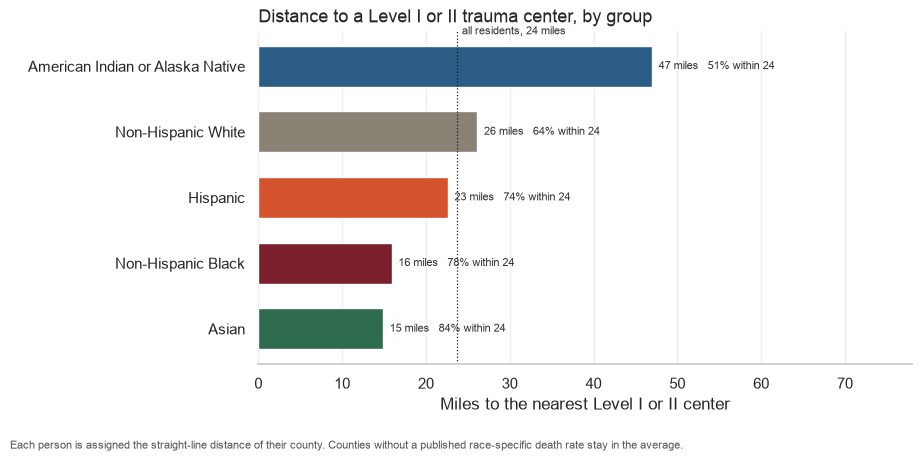

In [ ]:
access = counties.dropna(subset=["distance_miles", "population"]).copy()
access = access[access["population"] > 0]
ACCESS_GROUPS = [
    ("Asian", "pct_asian", "#2f6b4f"),
    ("Non-Hispanic Black", "pct_black", "#7a1f2b"),
    ("Hispanic", "pct_hispanic", "#d4532c"),
    ("Non-Hispanic White", "pct_white", "#8a8175"),
    ("American Indian or Alaska Native", "pct_aian", "#2c5d86"),
]
national_miles = float(np.average(access["distance_miles"], weights=access["population"]))
access_rows = []
for name, column, color in ACCESS_GROUPS:
    weights = access["population"] * access[column] / 100
    miles = float(np.average(access["distance_miles"], weights=weights))
    within = float(np.average(access["distance_miles"] <= national_miles, weights=weights))
    access_rows.append(
        {
            "group": name,
            "people": float(weights.sum()),
            "miles": miles,
            "within national average": within,
            "color": color,
        }
    )
access_table = pd.DataFrame(access_rows)
display(access_table.drop(columns="color").assign(
    people=lambda frame: frame["people"].map(lambda value: f"{value / 1e6:.1f} million"),
    miles=lambda frame: frame["miles"].map(lambda value: f"{value:.1f}"),
    **{"within national average": lambda frame: frame["within national average"].map(lambda value: f"{value:.0%}")},
))

fig, ax = plt.subplots(figsize=(9.2, 4.4))
positions = np.arange(len(access_table))
ax.barh(
    positions,
    access_table["miles"],
    color=access_table["color"],
    height=0.62,
    zorder=2,
)
ax.axvline(national_miles, color="#1a1a1a", linewidth=0.9, linestyle=":")
ax.text(
    national_miles + 0.6,
    len(access_table) - 0.55,
    f"all residents, {national_miles:.0f} miles",
    fontsize=8,
    color="#333333",
    va="bottom",
)
for position, row in access_table.iterrows():
    ax.text(
        row["miles"] + 0.8,
        position,
        f"{row['miles']:.0f} miles   {row['within national average']:.0%} within {national_miles:.0f}",
        va="center",
        fontsize=8,
        color="#333333",
    )
ax.set_yticks(positions)
ax.set_yticklabels(access_table["group"])
ax.set_xlabel("Miles to the nearest Level I or II center")
ax.set_xlim(0, 78)
ax.set_title("Distance to a Level I or II trauma center, by group", loc="left", fontsize=13)
ax.grid(axis="x", color="#eeeeee")
ax.grid(axis="y", visible=False)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
fig.text(
    0.0,
    -0.04,
    "Each person is assigned the straight-line distance of their county. Counties without a published race-specific death rate stay in the average.",
    fontsize=8,
    color="#555555",
)
fig.tight_layout()
fig.savefig(HERE / "distance_by_group.png", dpi=150, bbox_inches="tight")
plt.show()


## Mortality and distance classes

Counties with a published firearm rate are split at the resident-weighted national averages: the death rate, and the miles to a Level I or II center. Gray counties have no published rate.


High deaths, long trip: 1,259 counties, 56.1 million people
High deaths, short trip: 305 counties, 95.3 million people
Low deaths, long trip: 427 counties, 48.7 million people


Low deaths, short trip: 315 counties, 128.3 million people
No published rate: 838 counties, 6.5 million people
Split at 13.4 deaths per 100,000 and 23 miles.


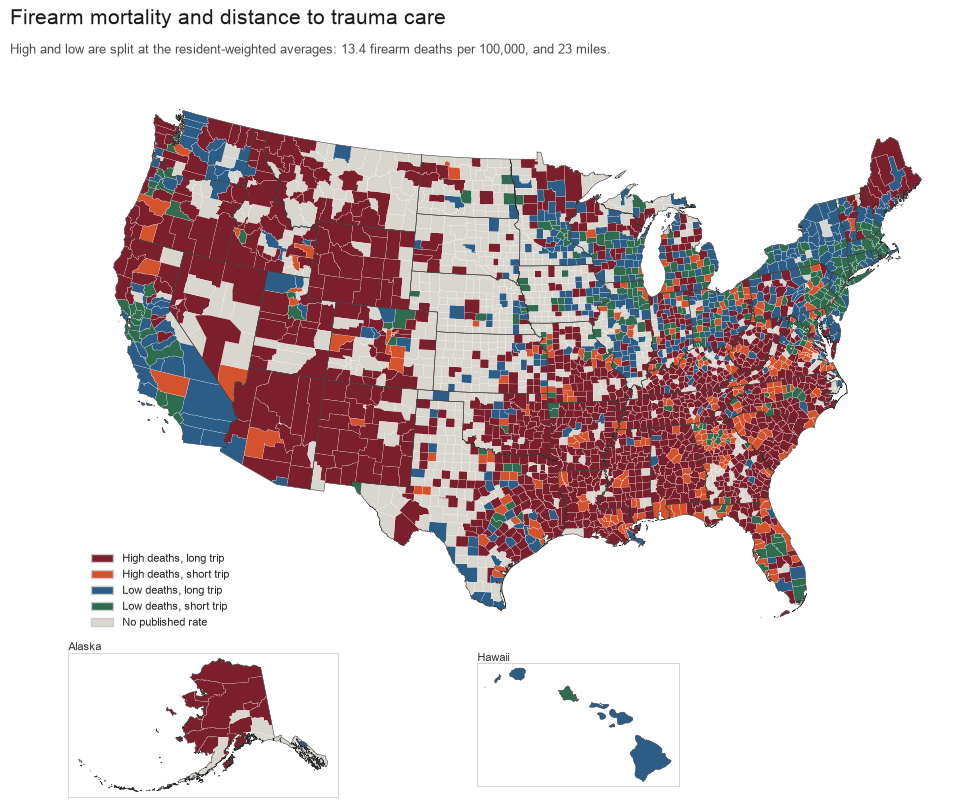

In [ ]:
classified = counties.dropna(subset=["distance_miles", "population"]).copy()
published = classified.dropna(subset=["firearm_rate"])
published = published[published["population"] > 0]
average_rate = float(np.average(published["firearm_rate"], weights=published["population"]))
average_distance = float(np.average(published["distance_miles"], weights=published["population"]))
high_deaths = classified["firearm_rate"] > average_rate
long_trip = classified["distance_miles"] > average_distance
missing = classified["firearm_rate"].isna()

HIGH_FAR = "#7a1f2b"
HIGH_NEAR = "#d4532c"
LOW_FAR = "#2c5d86"
LOW_NEAR = "#2f6b4f"
classified["_color"] = np.select(
    [
        missing,
        high_deaths & long_trip,
        high_deaths & ~long_trip,
        ~high_deaths & long_trip,
        ~high_deaths & ~long_trip,
    ],
    [MISSING, HIGH_FAR, HIGH_NEAR, LOW_FAR, LOW_NEAR],
    default=MISSING,
)
classified["corner"] = np.select(
    [
        missing,
        high_deaths & long_trip,
        high_deaths & ~long_trip,
        ~high_deaths & long_trip,
    ],
    [
        "No published rate",
        "High deaths, long trip",
        "High deaths, short trip",
        "Low deaths, long trip",
    ],
    default="Low deaths, short trip",
)
for label in [
    "High deaths, long trip",
    "High deaths, short trip",
    "Low deaths, long trip",
    "Low deaths, short trip",
    "No published rate",
]:
    part = classified[classified["corner"] == label]
    people = part["population"].sum()
    print(f"{label}: {len(part):,} counties, {people / 1e6:.1f} million people")
print(f"Split at {average_rate:.1f} deaths per 100,000 and {average_distance:.0f} miles.")

fig = plt.figure(figsize=(12.6, 8.4))
fig.text(0.03, 0.96, "Firearm mortality and distance to trauma care", fontsize=15, color="#1a1a1a")
fig.text(
    0.03,
    0.925,
    f"High and low are split at the resident-weighted averages: {average_rate:.1f} firearm deaths per 100,000, and {average_distance:.0f} miles.",
    fontsize=9,
    color="#4d4d4d",
)
map_box = (0.02, 0.04, 0.96, 0.86)
conus = draw_country(fig, map_box, classified)
conus.legend(
    handles=[
        Patch(facecolor=HIGH_FAR, edgecolor="#cccccc", label="High deaths, long trip"),
        Patch(facecolor=HIGH_NEAR, edgecolor="#cccccc", label="High deaths, short trip"),
        Patch(facecolor=LOW_FAR, edgecolor="#cccccc", label="Low deaths, long trip"),
        Patch(facecolor=LOW_NEAR, edgecolor="#cccccc", label="Low deaths, short trip"),
        Patch(facecolor=MISSING, edgecolor="#cccccc", label="No published rate"),
    ],
    loc="lower left",
    frameon=False,
    fontsize=8,
)
fig.savefig(HERE / "mortality_distance_classes.png", dpi=150)
plt.show()


## What this does not show

The slope is not the effect of building a trauma center, and it is not the effect of a longer ambulance ride on a person who has been shot.

The outcome mixes intents. Suicide is a large share of firearm deaths, and it is more common where counties are rural and centers are far. Density is a coarse stand-in for that mix. The homicide fit is there because it moves the outcome closer to interpersonal violence. It still uses every method of homicide, drops the counties CHR cannot publish, and still measures how often people die rather than how often people who were shot survive.

The distance is a centroid, a straight line, and a high-level center only. A town on the edge of a large county can be much closer to a hospital than the centroid is. A Level III center, a pediatric center, or a long drive on a slow road does not appear in the miles. HIFLD's text field misses state labels that never say "Level I" or "Level II."

Suppression is not random. Counties with few deaths, which tend to be small and often far, are missing from the weighted rates and from the colored classes on both maps. The gray counties are part of the pattern.

The combined map compares ranks among counties that have a published rate. A county can sit in the far third and still be much closer than the Aleutians. The race maps are who lives in the county. They are not a group's firearm death rate, and a county percentage is not a person's risk. Hispanic origin overlaps the race categories, so those shares are not slices of one total.
